# Charge–light matcher: t0-swap playground

A sandbox over the **v0.3.0** matcher's worst charge-TPCs (the D50 `--phase3 both
--force-coverage` run), pre-loaded with the pairwise-t0-**swap** failure examples so you
can look at event displays and prototype your own swap-detection algorithms.

**Run cells 1–6 once** to load the data + helpers. After that, drop your own snippets in the
scratch cells at the bottom — everything you need is in scope: the loaded event `EV`, the
current target `T`, and the `Event` helper methods.

### Environment
Use the NERSC module torch kernel so plotly + the M5p1 plotting tools import:
```bash
module load pytorch/2.8.0
cd /global/cfs/cdirs/dune/users/yuxuan/NDLAr-full/CLMatching_v0.1_backboneOnly/testing
jupyter lab   # or attach this .ipynb to that kernel
```
(Data extraction + matplotlib work under any numpy env; only the 3D plotly displays need the
M5p1 tools.)

### What's a 'swap'
When two interactions share one charge-TPC, the matcher sometimes gives each the *other's*
scintillation flash (t0). 91% of the non-shower wrong energy is this. A hit is **correct** iff
`|reco_t0 - truth_t0| <= 10 ticks (160 ns)`. The light peak of a cluster at t0 sits at tick
`t0 + 105`.

## 1 · Imports, paths, constants

In [1]:
import os, sys, json, glob
import numpy as np
import matplotlib.pyplot as plt

HERE = '/global/cfs/cdirs/dune/users/yuxuan/NDLAr-full/CLMatching_v0.1_backboneOnly/testing'
DUMPS = os.path.join(HERE, 'v030v3_out', 'dumps')   # v0.3 (D50 + per-TPC swap-fix)
if not os.path.isdir(DUMPS): DUMPS = os.path.join(HERE, 'v030D50fix_out', 'dumps')
GALLERY = os.path.join(HERE, 'bad_tpc_gallery')          # pre-rendered displays + context

# make the CLMatching light utilities importable (timeinterpolation, M5p1 plotting)
BASE = os.path.join(HERE, '..', 'CLMatching_AlphaRelease')
for p in (HERE, BASE, os.path.join(BASE, 'NewMLSection'), os.path.join(BASE, 'M5p1')):
    p = os.path.abspath(p)
    if p not in sys.path: sys.path.append(p)
from pulse_shapes import timeinterpolation           # shift a light template to a t0

PEAK   = 105       # light peak sits at tick  t0 + PEAK
CUT    = 10.0      # correctness threshold (ticks)
CLIP   = 60780.0   # ADC saturation level
GAIN   = 200.0     # for Poisson variance:  var = GAIN * max(actual, 100)
print('paths set; dumps present:', len(glob.glob(os.path.join(DUMPS, '*.npz'))))

paths set; dumps present: 39


## 2 · The `Event` object — your data API

`load_event(file, event)` returns an `Event` holding every per-hit array plus the full
actual/predicted light, and exposes the extraction helpers you'll build algorithms on.

| method | returns |
|---|---|
| `EV.actual_light(tpc)` | `[120, 1000]` **actual** scintillation light for that charge-TPC |
| `EV.predicted_light(tpc)` | `[120, 1000]` matcher's **predicted** light (sum of placed clusters) |
| `EV.template(L, tpc)` | `[120, 1000]` cluster `L`'s per-channel light image (ML prediction), or `None` |
| `EV.place(L, tpc, t0)` | that template time-shifted to `t0` (peak at `t0+105`) |
| `EV.t0(L)` / `EV.truth(L)` | cluster `L`'s reco / true t0 |
| `EV.energy(L)` / `EV.hits(L)` | cluster energy / boolean hit mask |
| `EV.clusters_in_tpc(tpc)` | labels present in that TPC (energy-sorted) |
| `EV.flash_profile(tpc, t0)` | `(profile[120], sat_mask[120])` spatial pattern of the actual light at a flash |
| `EV.spatial_cos(L, tpc, t0)` | saturation-masked cosine of `L`'s template vs the actual flash at `t0` |

Note: the dumps keep per-cluster templates only for the ~8 worst clusters per event (to save
disk), so `EV.template(L, tpc)` is `None` for most small clusters — but it **is** present for the
dominant swap clusters in the targets below. `actual_light`/`predicted_light` are always full.

In [2]:
class Event:
    def __init__(self, npz, file, event):
        self.file, self.event = file, event
        for k in ('x','y','z','e','tpc','labels','ts_final','ts_p1','truth_t0'):
            setattr(self, k, np.asarray(npz[k]))
        self.full_light = np.asarray(npz['full_light'], np.float64)   # [70,120,1000] actual
        self.base_image = np.asarray(npz['base_image'], np.float64)   # [70,120,1000] predicted
        self.templates = {}
        for k in npz.files:
            if k.startswith('img_'):
                _, L, c = k.split('_'); self.templates[(int(L), int(c))] = np.asarray(npz[k], np.float64)
        self.lab_rows = {r['label']: r for r in json.loads(str(npz['lab_rows']))}
    # --- light ---
    def actual_light(self, tpc):    return self.full_light[tpc]         # [120,1000]
    def predicted_light(self, tpc): return self.base_image[tpc]         # [120,1000]
    def template(self, L, tpc):     return self.templates.get((int(L), int(tpc)))
    def place(self, L, tpc, t0):
        P = self.template(L, tpc)
        return None if P is None else timeinterpolation(P, shift=float(t0), baseline=0)
    # --- clusters ---
    def hits(self, L):   return self.labels == L
    def energy(self, L): return float(self.e[self.labels == L].sum())
    def t0(self, L):
        m = (self.labels == L) & np.isfinite(self.ts_final)
        return float(np.median(self.ts_final[m])) if m.any() else None
    def truth(self, L):
        m = (self.labels == L) & np.isfinite(self.truth_t0)
        return float(np.median(self.truth_t0[m])) if m.any() else None
    def clusters_in_tpc(self, tpc):
        ls = np.unique(self.labels[(self.tpc == tpc) & (self.labels >= 0)])
        return sorted((int(L) for L in ls), key=lambda L: -self.energy(L))
    # --- light spatial pattern + discriminator ---
    def flash_profile(self, tpc, t0, win=4):
        a = self.full_light[tpc]; t = int(round(t0)) + PEAK
        lo, hi = max(0, t - win), min(a.shape[1], t + win + 1)
        col = a[:, lo:hi]
        return col.sum(1), col.max(1) >= 0.98 * CLIP        # profile[120], saturated mask
    def spatial_cos(self, L, tpc, t0, win=4):
        P = self.template(L, tpc)
        if P is None: return None
        tmpl = P.sum(1)                                     # cluster spatial template
        prof, sat = self.flash_profile(tpc, t0, win)
        a, b = tmpl[~sat], prof[~sat]
        na, nb = np.linalg.norm(a), np.linalg.norm(b)
        return float(a @ b / (na * nb)) if na and nb else 0.0

def load_event(file, event):
    npz = np.load(os.path.join(DUMPS, f'{file}_ev{event}.npz'), allow_pickle=True)
    return Event(npz, file, event)
print('Event class ready')

Event class ready


## 3 · The failure targets (pairwise-swap examples)

Ten of the worst non-shower TPCs, each with its dominant wrong cluster(s). `swap_pair` names two
clusters that (should) exchange t0s. `b0` (TPC 5) has **both** partners' templates — the cleanest
worked example. Pre-rendered 3D displays live in `bad_tpc_gallery/b{i}_*`.

In [3]:
TARGETS = [
 {
  "i": 0,
  "file": "0000001",
  "event": 12,
  "tpc": 38,
  "eff": 0.424,
  "wrongE": 739.3,
  "swap_pair": [
   1440,
   87
  ],
  "clusters": [
   {
    "L": 1440,
    "E": 339.7,
    "placed": 490.0,
    "true": 386.3,
    "type": "cluster"
   },
   {
    "L": 87,
    "E": 139.3,
    "placed": 349.5,
    "true": 490.1,
    "type": "track"
   }
  ]
 },
 {
  "i": 1,
  "file": "0000002",
  "event": 8,
  "tpc": 61,
  "eff": 0.432,
  "wrongE": 557.0,
  "swap_pair": [
   122,
   125
  ],
  "clusters": [
   {
    "L": 122,
    "E": 158.8,
    "placed": 523.0,
    "true": 287.0,
    "type": "track"
   },
   {
    "L": 125,
    "E": 140.0,
    "placed": 599.0,
    "true": 522.3,
    "type": "track"
   }
  ]
 },
 {
  "i": 2,
  "file": "0000001",
  "event": 3,
  "tpc": 69,
  "eff": 0.525,
  "wrongE": 492.1,
  "swap_pair": [
   3,
   1370
  ],
  "clusters": [
   {
    "L": 3,
    "E": 394.7,
    "placed": 160.0,
    "true": 507.7,
    "type": "shower"
   },
   {
    "L": 1370,
    "E": 23.7,
    "placed": 508.0,
    "true": 159.8,
    "type": "cluster"
   }
  ]
 },
 {
  "i": 3,
  "file": "0000003",
  "event": 3,
  "tpc": 24,
  "eff": 0.585,
  "wrongE": 455.4,
  "swap_pair": [
   69,
   0
  ],
  "clusters": [
   {
    "L": 69,
    "E": 83.0,
    "placed": 47.0,
    "true": 303.1,
    "type": "track"
   },
   {
    "L": 0,
    "E": 154.2,
    "placed": 211.0,
    "true": 210.1,
    "type": "shower"
   }
  ]
 },
 {
  "i": 4,
  "file": "0000002",
  "event": 6,
  "tpc": 1,
  "eff": 0.564,
  "wrongE": 385.0,
  "swap_pair": [
   0,
   178
  ],
  "clusters": [
   {
    "L": 0,
    "E": 471.1,
    "placed": 252.0,
    "true": 251.7,
    "type": "shower"
   },
   {
    "L": 178,
    "E": 19.3,
    "placed": 252.0,
    "true": 130.6,
    "type": "cluster"
   }
  ]
 },
 {
  "i": 5,
  "file": "0000002",
  "event": 7,
  "tpc": 23,
  "eff": 0.649,
  "wrongE": 383.4,
  "swap_pair": [
   51,
   62
  ],
  "clusters": [
   {
    "L": 51,
    "E": 151.9,
    "placed": 260.0,
    "true": 403.3,
    "type": "track"
   },
   {
    "L": 62,
    "E": 146.2,
    "placed": 404.0,
    "true": 259.3,
    "type": "track"
   }
  ]
 },
 {
  "i": 6,
  "file": "0000001",
  "event": 12,
  "tpc": 2,
  "eff": 0.769,
  "wrongE": 276.3,
  "swap_pair": [
   9,
   265
  ],
  "clusters": [
   {
    "L": 9,
    "E": 313.0,
    "placed": 348.5,
    "true": 590.6,
    "type": "track"
   },
   {
    "L": 265,
    "E": 24.3,
    "placed": 617.0,
    "true": 590.6,
    "type": "cluster"
   }
  ]
 },
 {
  "i": 7,
  "file": "0000002",
  "event": 4,
  "tpc": 64,
  "eff": 0.691,
  "wrongE": 273.6,
  "swap_pair": [
   107,
   1081
  ],
  "clusters": [
   {
    "L": 107,
    "E": 136.9,
    "placed": 364.0,
    "true": 150.3,
    "type": "track"
   },
   {
    "L": 1081,
    "E": 293.7,
    "placed": 150.5,
    "true": 150.2,
    "type": "cluster"
   }
  ]
 },
 {
  "i": 8,
  "file": "0000002",
  "event": 12,
  "tpc": 37,
  "eff": 0.758,
  "wrongE": 187.9,
  "swap_pair": [
   86,
   1171
  ],
  "clusters": [
   {
    "L": 86,
    "E": 174.5,
    "placed": 135.0,
    "true": 123.0,
    "type": "track"
   },
   {
    "L": 1171,
    "E": 7.3,
    "placed": 32.0,
    "true": 148.0,
    "type": "cluster"
   }
  ]
 },
 {
  "i": 9,
  "file": "0000002",
  "event": 12,
  "tpc": 35,
  "eff": 0.9,
  "wrongE": 59.2,
  "swap_pair": [
   86,
   1127
  ],
  "clusters": [
   {
    "L": 86,
    "E": 53.2,
    "placed": 135.0,
    "true": 122.8,
    "type": "track"
   },
   {
    "L": 1127,
    "E": 1.9,
    "placed": 58.5,
    "true": 213.0,
    "type": "cluster"
   }
  ]
 }
]

print(f'{len(TARGETS)} targets:')
for t in TARGETS:
    cs = ' / '.join(f"L{c['L']}({c['E']:.0f}MeV placed {c['placed']}->true {c['true']})" for c in t['clusters'])
    print(f"  b{t['i']}: {t['file']} ev{t['event']} TPC{t['tpc']:<3} eff={t['eff']:.2f} wrongE={t['wrongE']:.0f}  | {cs}")

10 targets:
  b0: 0000001 ev12 TPC38  eff=0.42 wrongE=739  | L1440(340MeV placed 490.0->true 386.3) / L87(139MeV placed 349.5->true 490.1)
  b1: 0000002 ev8 TPC61  eff=0.43 wrongE=557  | L122(159MeV placed 523.0->true 287.0) / L125(140MeV placed 599.0->true 522.3)
  b2: 0000001 ev3 TPC69  eff=0.53 wrongE=492  | L3(395MeV placed 160.0->true 507.7) / L1370(24MeV placed 508.0->true 159.8)
  b3: 0000003 ev3 TPC24  eff=0.58 wrongE=455  | L69(83MeV placed 47.0->true 303.1) / L0(154MeV placed 211.0->true 210.1)
  b4: 0000002 ev6 TPC1   eff=0.56 wrongE=385  | L0(471MeV placed 252.0->true 251.7) / L178(19MeV placed 252.0->true 130.6)
  b5: 0000002 ev7 TPC23  eff=0.65 wrongE=383  | L51(152MeV placed 260.0->true 403.3) / L62(146MeV placed 404.0->true 259.3)
  b6: 0000001 ev12 TPC2   eff=0.77 wrongE=276  | L9(313MeV placed 348.5->true 590.6) / L265(24MeV placed 617.0->true 590.6)
  b7: 0000002 ev4 TPC64  eff=0.69 wrongE=274  | L107(137MeV placed 364.0->true 150.3) / L1081(294MeV placed 150.5->true

## 4 · Pick a target and load it

Change `PICK` to any index above. `b0` (TPC 5) is the recommended starting point (both swap
templates available).

In [21]:
PICK = 2
T   = TARGETS[PICK]
EV  = load_event(T['file'], T['event'])
TPC = T['tpc']
print(f"loaded {T['file']} ev{T['event']}  TPC {TPC}  (eff={T['eff']:.2f})")
print('clusters in this TPC (energy-sorted):', EV.clusters_in_tpc(TPC)[:12])
for c in T['clusters']:
    L = c['L']
    print(f"  L{L}: E={EV.energy(L):.0f}MeV  reco_t0={EV.t0(L):.1f}  true_t0={EV.truth(L):.1f}  "
          f"template={'yes' if EV.template(L, TPC) is not None else 'NO'}")

loaded 0000001 ev3  TPC 69  (eff=0.53)
clusters in this TPC (energy-sorted): [125, 3, 133, 134, 1376, 1370, 1405, 135, 1400, 1377, 1402, 1403]
  L3: E=395MeV  reco_t0=160.0  true_t0=507.7  template=yes
  L1370: E=32MeV  reco_t0=508.0  true_t0=159.9  template=NO


## 5 · Extract the actual & predicted light (the building blocks)

This is the kind of snippet you asked for — grab the current actual vs predicted light for the
TPC, and any cluster's own template.

actual/predicted light shape: (120, 1000) (120, 1000)
cluster 3: E=395MeV  reco 160 / true 508
cluster 1370: E=32MeV  reco 508 / true 160


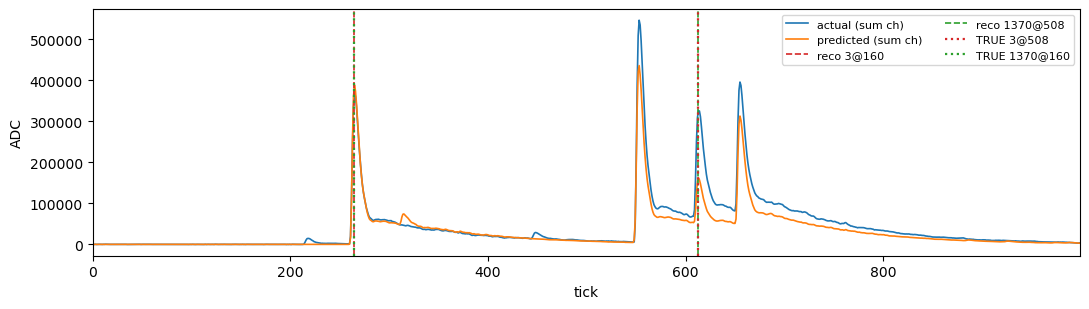

In [22]:
act  = EV.actual_light(TPC)      # [120, 1000]  what the light detectors saw
pred = EV.predicted_light(TPC)   # [120, 1000]  what the matcher's assignment predicts
print('actual/predicted light shape:', act.shape, pred.shape)

# the two swap clusters and their own light templates (unshifted ML images)
A, B = T['swap_pair']
tA, tB = EV.t0(A), EV.t0(B)
PA = EV.place(A, TPC, tA)   # cluster A's template placed at its current reco t0  -> [120,1000]
PB = EV.place(B, TPC, tB)
print(f'cluster {A}: E={EV.energy(A):.0f}MeV  reco {tA:.0f} / true {EV.truth(A):.0f}')
print(f'cluster {B}: E={EV.energy(B):.0f}MeV  reco {tB:.0f} / true {EV.truth(B):.0f}')

# quick look: light summed over channels vs tick, with the two flashes marked
fig, ax = plt.subplots(figsize=(11,3.2))
ax.plot(act.sum(0),  label='actual (sum ch)',    lw=1.2)
ax.plot(pred.sum(0), label='predicted (sum ch)', lw=1.2)
for t0, lab, col in [(tA, f'{A}@{tA:.0f}', 'C3'), (tB, f'{B}@{tB:.0f}', 'C2')]:
    ax.axvline(t0 + PEAK, color=col, ls='--', lw=1.2, label=f'reco {lab}')
for L, col in [(A, 'C3'), (B, 'C2')]:
    tr = EV.truth(L)
    if tr is not None: ax.axvline(tr + PEAK, color=col, ls=':', lw=1.6, label=f'TRUE {L}@{tr:.0f}')
ax.set_xlabel('tick'); ax.set_ylabel('ADC'); ax.legend(fontsize=8, ncol=2); ax.set_xlim(0, 999)
plt.tight_layout(); plt.show()

## 6 · Worked example — the masked spatial-cosine discriminator

The physical signal that separates the correct from the swapped assignment: each flash's
**per-channel spatial pattern** is set by the interaction's *position*, so a cluster's template
matches the actual light at its **true** flash better than at its **placed** (wrong) flash —
with **saturated channels masked** (they carry no spatial info). This is what `swap_fix.py` uses.

In [23]:
for L in (A, B):
    cp = EV.spatial_cos(L, TPC, EV.t0(L))      # cosine at its current (placed) flash
    ct = EV.spatial_cos(L, TPC, EV.truth(L))   # cosine at its true flash
    print(f'cluster {L}:  cos@placed({EV.t0(L):.0f}) = {cp:.3f}   cos@true({EV.truth(L):.0f}) = {ct:.3f}'
          f'   -> prefers {"TRUE" if ct > cp else "placed"}')

# generalize: score cluster A against EVERY flash occupied in this TPC
occupied = sorted({round(EV.t0(L)) for L in EV.clusters_in_tpc(TPC) if EV.t0(L) is not None})
print(f'\ncluster {A} spatial-cos vs each occupied flash t0 in TPC {TPC}:')
for t0 in occupied:
    print(f'   t0={t0:>4}: cos = {EV.spatial_cos(A, TPC, t0):.3f}')

cluster 3:  cos@placed(160) = 0.702   cos@true(508) = 0.943   -> prefers TRUE


TypeError: unsupported format string passed to NoneType.__format__

## 7 · Event displays

Pre-rendered interactive 3D + light/charge for this target are in `bad_tpc_gallery/`:
open the `.html` files (rotatable) or view the `.png`. To (re)render inline for any TPC, run the
cell below — it uses the same M5p1 tools as the gallery (needs the pytorch/2.8.0 kernel).

pre-rendered files:


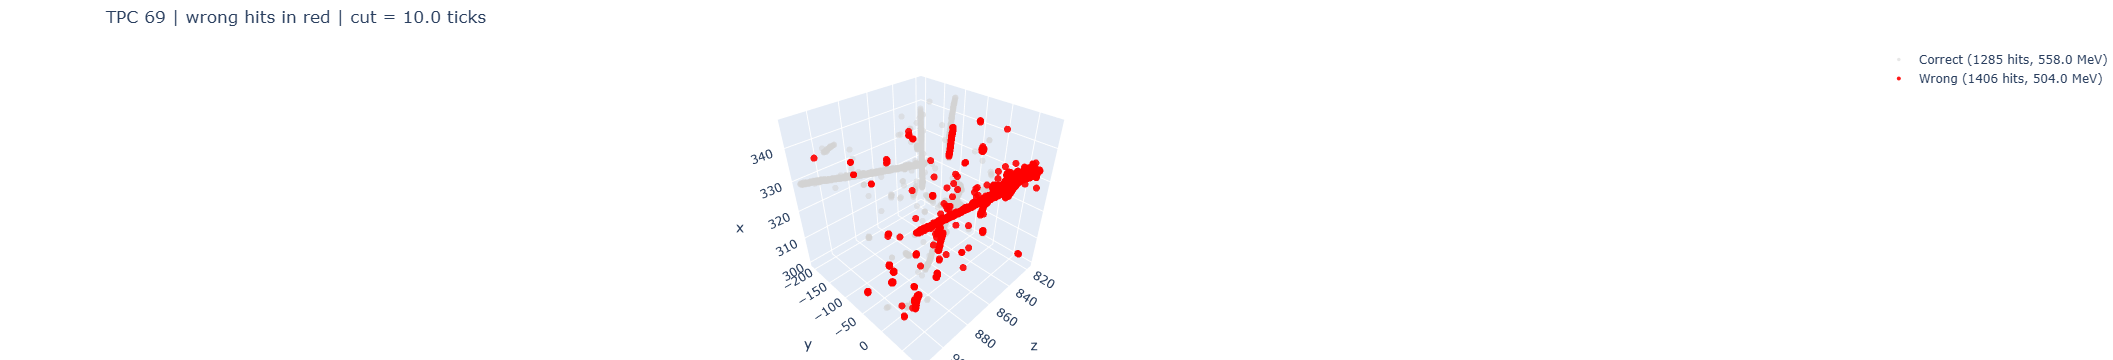

TPC 69
Residual cut                 : 10.00 ticks (160 ns)
Finite truth+reco hits       : 2691
Wrong hits                   : 1406
Correct energy               : 558.0290 MeV
Wrong energy                 : 503.9689 MeV
Correct energy fraction      : 52.55%
Wrong energy fraction        : 47.45%


In [24]:
stem = f"b{T['i']}_{T['file']}_ev{T['event']}_tpc{TPC}"
print('pre-rendered files:')
for k in ('wrong3d', 'reco3d', 'truth3d', 'light_charge'):
    for ext in ('html', 'png'):
        p = os.path.join(GALLERY, f'{stem}_{k}.{ext}')
        if os.path.exists(p): print('  ', p)

# --- inline 3D (RED = wrong hits) ---
try:
    from M5p1 import plottingTools as pt
    from M5p1 import truth_plotting as tp
    m = EV.tpc == TPC
    tp.plot_wrong_hits_3d(int(TPC), EV.truth_t0, hit_timestamps=EV.ts_final, hitTPCid=EV.tpc,
                          xset=EV.x, yset=EV.y, zset=EV.z, Eset=EV.e, residual_cut_ticks=CUT,
                          marker_size=3.5, wrong_color='red', correct_color='lightgray', show=True)
except Exception as ex:
    print('inline 3D needs the pytorch/2.8.0 kernel + M5p1 tools; open the gallery .html instead.', ex)

family 1 (true~386): clusters [1440]  E=391 MeV  placed t0=490
family 2 (true~490): clusters [87, 125, 1444, 1442, 1441, 1446, 1437, 1447, 1438]  E=307 MeV  placed t0=387

CURRENT wrong energy :   759.1 MeV  (57.6% of TPC truth E)
SWAPPED wrong energy :   323.9 MeV  (24.6% of TPC truth E)
  -> swapping the two families HELPS (Δ = -435.2 MeV)

light-loss minimum at  family1@491, family2@356   (current 490,387 | swapped 387,490 | truth 386,490)


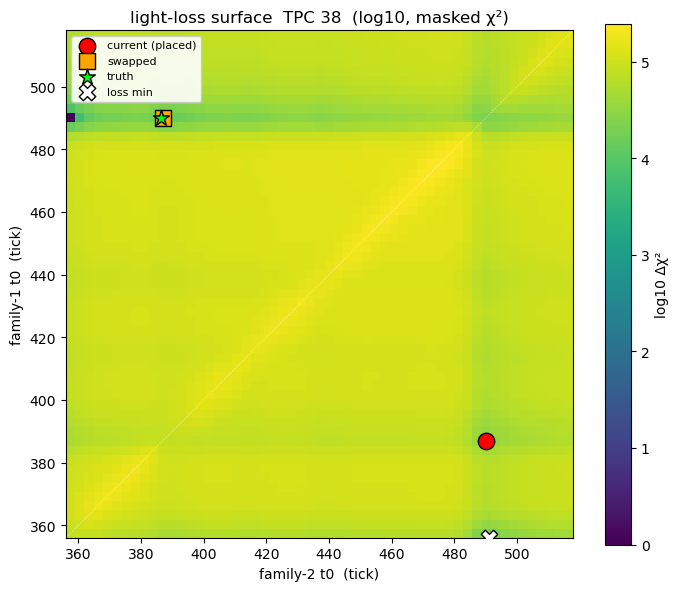

In [8]:
# ============================================================================
#  Swap test + 2D light-loss surface for the two families in this TPC
#  paste after cell 7.  In scope: EV, T, TPC, A, B, PEAK, CUT, CLIP, GAIN, timeinterpolation
# ============================================================================
# --- define the two families: all clusters truly at ~A's and ~B's true t0 ---
trA, trB = EV.truth(A), EV.truth(B)
def family(t_true, tol=10):
    return [L for L in EV.clusters_in_tpc(TPC)
            if EV.truth(L) is not None and abs(EV.truth(L) - t_true) <= tol]
fam1, fam2 = family(trA), family(trB)                 # lists of cluster labels
t1_cur = np.median([EV.t0(L) for L in fam1])          # family-1 current (placed) t0
t2_cur = np.median([EV.t0(L) for L in fam2])          # family-2 current (placed) t0
E1 = sum(EV.energy(L) for L in fam1); E2 = sum(EV.energy(L) for L in fam2)
print(f"family 1 (true~{trA:.0f}): clusters {fam1}  E={E1:.0f} MeV  placed t0={t1_cur:.0f}")
print(f"family 2 (true~{trB:.0f}): clusters {fam2}  E={E2:.0f} MeV  placed t0={t2_cur:.0f}")

# --- 1) current error vs SWAPPED error (energy-weighted, truth-based) --------
mtpc = (EV.tpc == TPC) & np.isfinite(EV.truth_t0)
def wrong_energy(ts):
    return float(EV.e[mtpc & (np.abs(ts - EV.truth_t0) > CUT)].sum())
E_truth = float(EV.e[mtpc].sum())
ts_cur = EV.ts_final.copy()
ts_swp = ts_cur.copy()
for L in fam1: ts_swp[EV.hits(L)] = t2_cur              # family 1 -> family 2's flash
for L in fam2: ts_swp[EV.hits(L)] = t1_cur              # family 2 -> family 1's flash
eW_c, eW_s = wrong_energy(ts_cur), wrong_energy(ts_swp)
print(f"\nCURRENT wrong energy : {eW_c:7.1f} MeV  ({100*eW_c/E_truth:.1f}% of TPC truth E)")
print(f"SWAPPED wrong energy : {eW_s:7.1f} MeV  ({100*eW_s/E_truth:.1f}% of TPC truth E)")
print(f"  -> swapping the two families {'HELPS' if eW_s < eW_c else 'does NOT help'} "
      f"(Δ = {eW_s - eW_c:+.1f} MeV)")

# --- 2) 2D light-loss surface  L(t0=family1, t1=family2) ---------------------
# each family's total template = sum of its clusters' dumped templates (those that have one)
def fam_template(fam):
    Ps = [EV.template(L, TPC) for L in fam if EV.template(L, TPC) is not None]
    return None if not Ps else np.sum(Ps, axis=0)          # [120,1000]
P1, P2 = fam_template(fam1), fam_template(fam2)
assert P1 is not None and P2 is not None, "a family has no dumped template; use target b0 (both present)"

act    = EV.actual_light(TPC)                              # [120,1000]
base_wo = EV.predicted_light(TPC) \
          - sum(EV.place(L, TPC, EV.t0(L)) for L in fam1 if EV.template(L, TPC) is not None) \
          - sum(EV.place(L, TPC, EV.t0(L)) for L in fam2 if EV.template(L, TPC) is not None)
supp = (P1.sum(1) > 0.01*P1.sum(1).max()) | (P2.sum(1) > 0.01*P2.sum(1).max())   # channels that matter

lo   = int(min(trA, trB, t1_cur, t2_cur)) - 30
hi   = int(max(trA, trB, t1_cur, t2_cur)) + 30
grid = np.arange(lo, hi + 1, 3)
tlo, thi = max(0, lo + PEAK - 15), min(act.shape[1], hi + PEAK + 60)
act_s  = act[np.ix_(supp, np.arange(tlo, thi))]
base_s = base_wo[np.ix_(supp, np.arange(tlo, thi))]
var_s  = GAIN * np.maximum(act_s, 100.0)
mask_s = act_s < 0.98*CLIP                                 # keep UNsaturated channels only
sh1 = {t: timeinterpolation(P1, shift=float(t), baseline=0)[np.ix_(supp, np.arange(tlo, thi))] for t in grid}
sh2 = {t: timeinterpolation(P2, shift=float(t), baseline=0)[np.ix_(supp, np.arange(tlo, thi))] for t in grid}
def light_loss(a, b):
    d = (np.minimum(base_s + sh1[a] + sh2[b], CLIP) - act_s)**2 / var_s
    return float(d[mask_s].sum())
Lsurf = np.array([[light_loss(a, b) for b in grid] for a in grid])   # rows=t0(fam1), cols=t1(fam2)

imin = np.unravel_index(np.argmin(Lsurf), Lsurf.shape)
print(f"\nlight-loss minimum at  family1@{grid[imin[0]]}, family2@{grid[imin[1]]}   "
      f"(current {t1_cur:.0f},{t2_cur:.0f} | swapped {t2_cur:.0f},{t1_cur:.0f} | truth {trA:.0f},{trB:.0f})")

fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(np.log10(Lsurf - Lsurf.min() + 1), origin='lower', cmap='viridis',
               extent=[grid[0], grid[-1], grid[0], grid[-1]], aspect='equal')
ax.plot([grid[0], grid[-1]], [grid[0], grid[-1]], 'w:', lw=0.8, alpha=0.5)     # t0==t1 diagonal
for (x, y, mk, col, lab) in [(t1_cur, t2_cur, 'o', 'red',   'current (placed)'),
                             (t2_cur, t1_cur, 's', 'orange','swapped'),
                             (trA,    trB,    '*', 'lime',  'truth'),
                             (grid[imin[0]], grid[imin[1]], 'X', 'white', 'loss min')]:
    ax.scatter([x], [y], marker=mk, s=140, edgecolors='k', facecolors=col, label=lab, zorder=5)
ax.set_xlabel('family-2 t0  (tick)'); ax.set_ylabel('family-1 t0  (tick)')
ax.set_title(f'light-loss surface  TPC {TPC}  (log10, masked χ²)')
ax.legend(loc='upper left', fontsize=8, framealpha=0.9)
plt.colorbar(im, ax=ax, label='log10 Δχ²'); plt.tight_layout(); plt.show()


===== BEFORE swap:  family1 @ 490, family2 @ 387 =====
Total energy in TPC 69: 1062.00


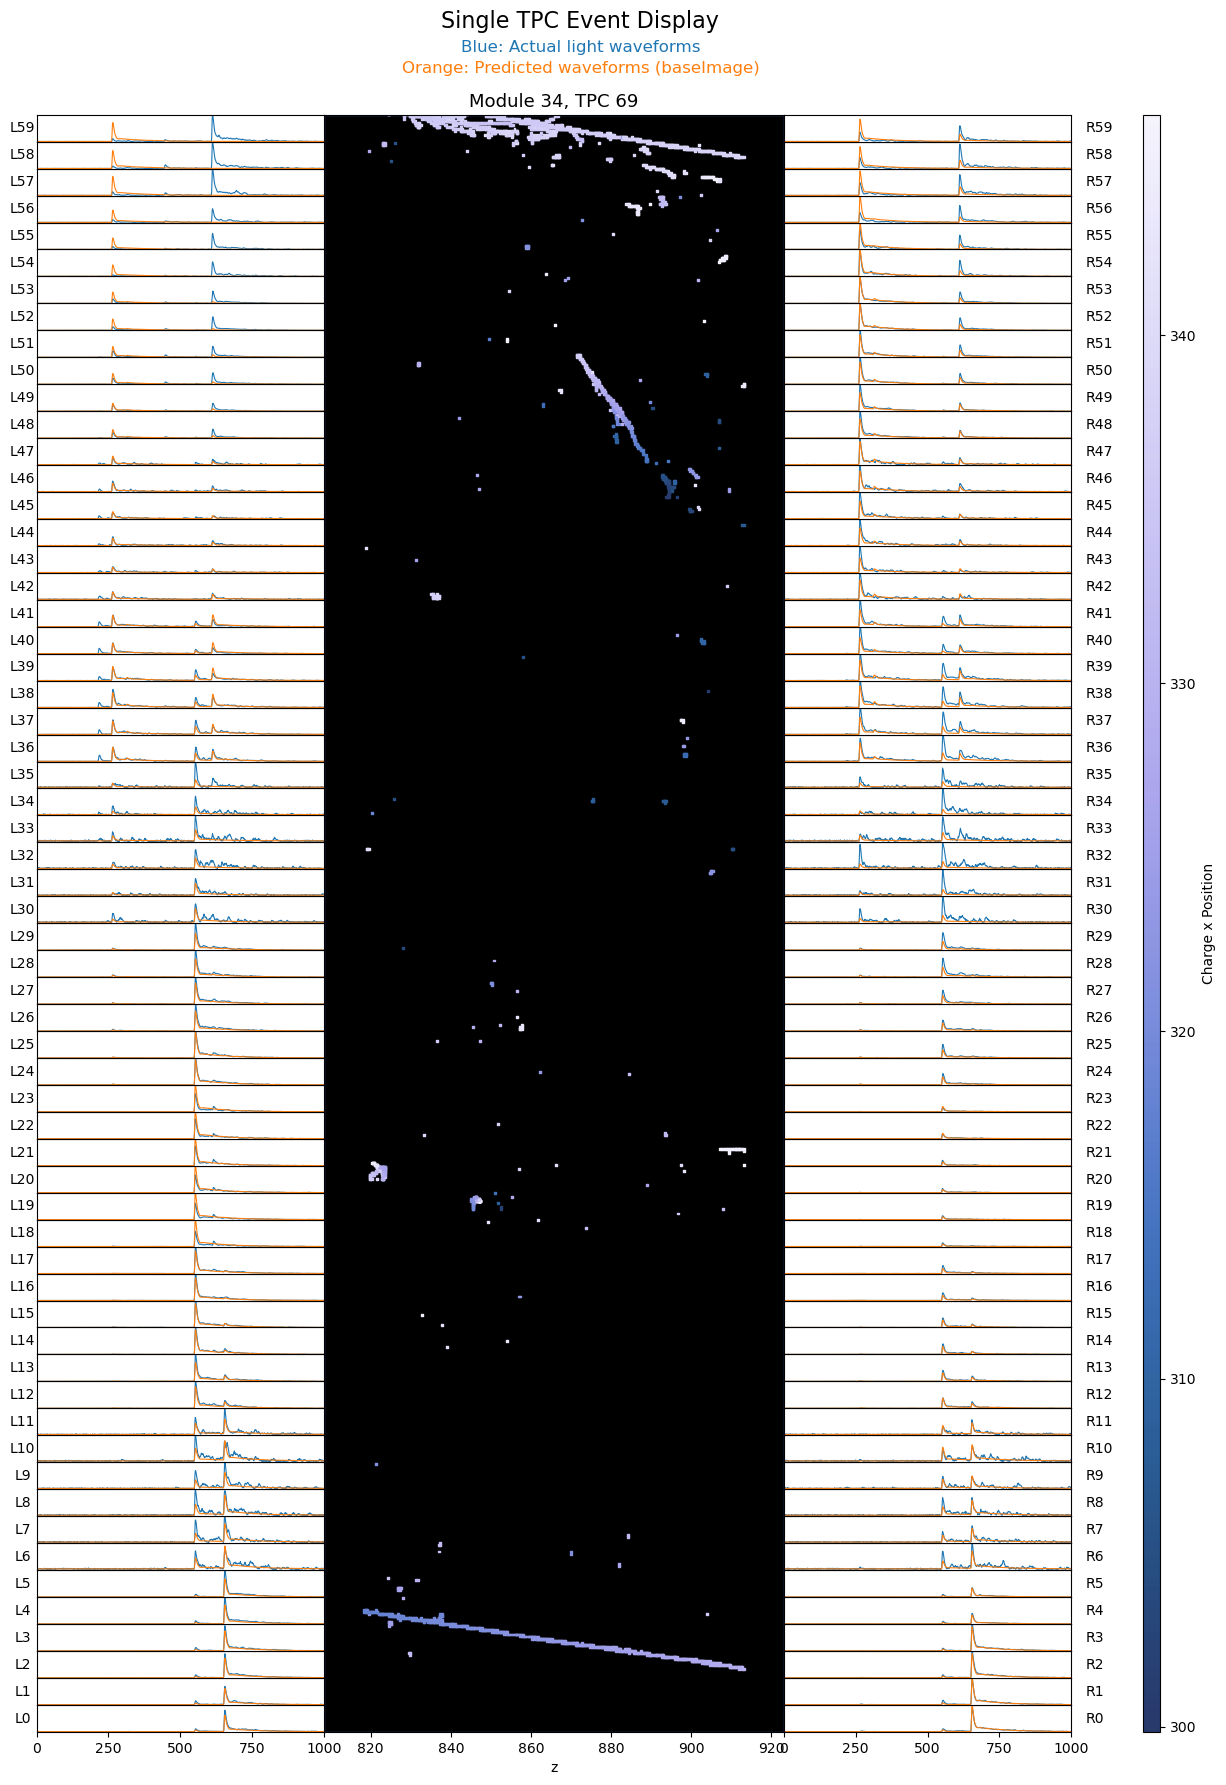

===== AFTER swap:   family1 @ 387, family2 @ 490  (= truth 386/490) =====
Total energy in TPC 69: 1062.00


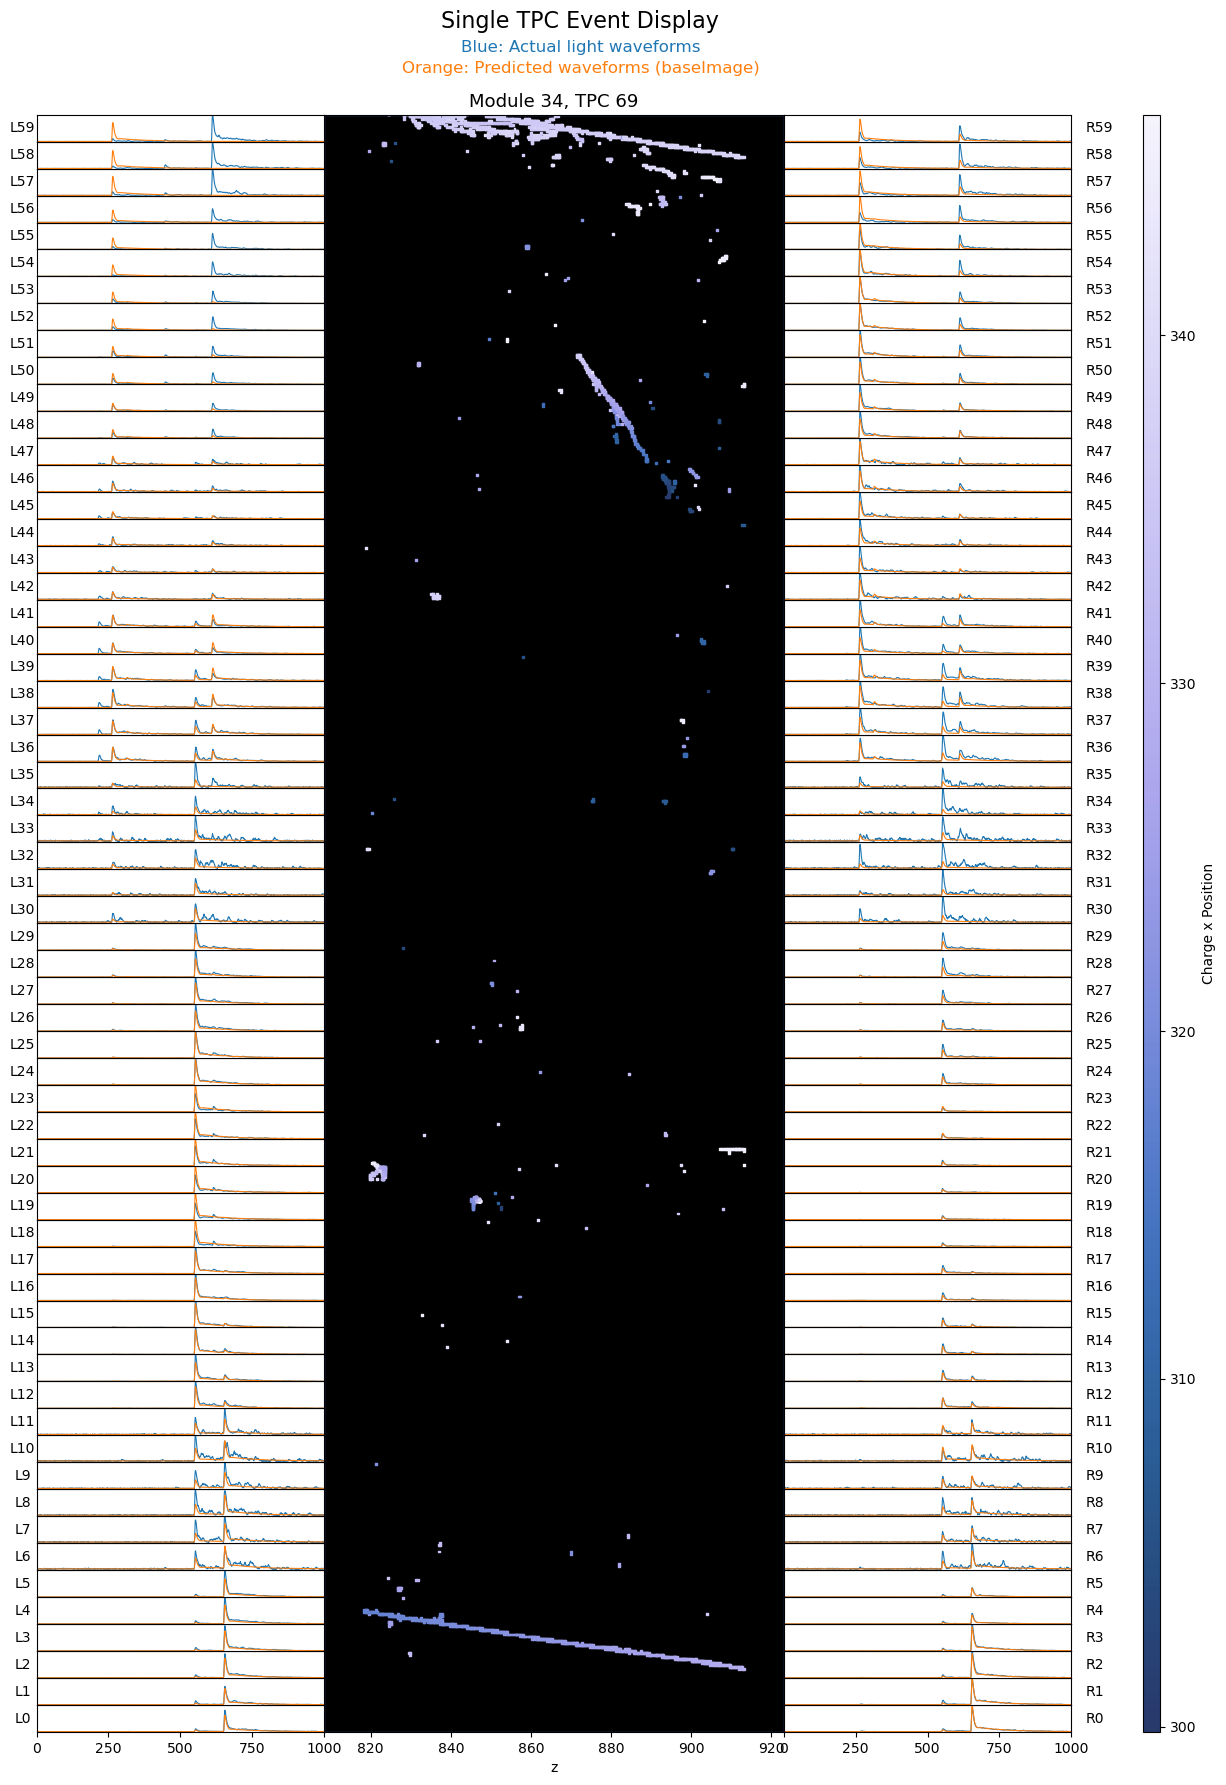

In [25]:
# ============================================================================
#  Per-channel light waveforms: cumulative PREDICTED light, BEFORE vs AFTER swap
#  two separate figures (plot_tpc_light_and_charge style). needs the previous cell's
#  fam1, fam2, t1_cur, t2_cur.  Kernel: pytorch/2.8.0 (M5p1 tools).
# ============================================================================
from M5p1 import visualizationTools as vt

# hits record array the plotter expects (io_group selects the TPC: 2*tpc+1,2*tpc+2)
_dt = np.dtype([('io_group', 'i4'), ('x', 'f8'), ('y', 'f8'), ('z', 'f8'), ('E', 'f8')])
hits_full = np.zeros(len(EV.x), dtype=_dt)
hits_full['io_group'] = 2 * EV.tpc + 1
hits_full['x'], hits_full['y'], hits_full['z'], hits_full['E'] = EV.x, EV.y, EV.z, EV.e

actual_wf = EV.actual_light(TPC)                       # [120,1000] blue

# BEFORE = current cumulative predicted (matcher's baseImage for this TPC)
pred_before = np.minimum(EV.predicted_light(TPC).copy(), CLIP)

# AFTER = remove both families at their current t0, re-add at each OTHER's t0
base_wo = EV.predicted_light(TPC).copy()
for L in fam1 + fam2:
    p = EV.place(L, TPC, EV.t0(L))
    if p is not None: base_wo -= p
pred_after = base_wo.copy()
for L in fam1:                                         # family 1 -> family 2's flash
    p = EV.place(L, TPC, t2_cur)
    if p is not None: pred_after += p
for L in fam2:                                         # family 2 -> family 1's flash
    p = EV.place(L, TPC, t1_cur)
    if p is not None: pred_after += p
pred_after = np.minimum(pred_after, CLIP)

print(f"===== BEFORE swap:  family1 @ {t1_cur:.0f}, family2 @ {t2_cur:.0f} =====")
vt.plot_tpc_light_and_charge(EV.event, TPC, hits_full, actual_wf, predicted=pred_before)

print(f"===== AFTER swap:   family1 @ {t2_cur:.0f}, family2 @ {t1_cur:.0f}  (= truth {trA:.0f}/{trB:.0f}) =====")
vt.plot_tpc_light_and_charge(EV.event, TPC, hits_full, actual_wf, predicted=pred_after)


## 8 · Run / experiment with the swap-fix algorithm

`swap_fix.run_swap_correction` implements the mutual-confirmation pairwise swap (with margin
whitening). Here it runs on just this target's two clusters so you can watch it fire and inspect
the audit. Tune `min_cos_gain`, `whiten`, `min_energy`, or swap in your **own** `pair_gains`.

In [10]:
import importlib, swap_fix; importlib.reload(swap_fix)

def truth_fn(L): return EV.truth(L)

# build a minimal namespace with just the swap pair (so the run is easy to reason about)
A, B = T['swap_pair']
ns = dict(
    imageMaps    = {(A, TPC): EV.template(A, TPC), (B, TPC): EV.template(B, TPC)},
    fullLightWaveform = EV.full_light,
    baseImage    = EV.base_image.copy(),
    labels_global = EV.labels,
    hit_timestamps = EV.ts_final.astype(np.float32).copy(),
    Eset         = EV.e,
)
# NOTE: whiten=True subtracts the TPC's MEAN flash; with only 2 clusters in `ns` that mean is
# degenerate, so the isolated demo uses whiten=False (raw cosine, which fires on a clean pair).
# In the real pipeline the TPC has many clusters, so the mean flash is proper and whiten=True is used.
st = swap_fix.run_swap_correction(ns, hit_tpc=EV.tpc, cluster_to_tpcs={A: [TPC], B: [TPC]},
                                  min_energy=25.0, chi2_ratio_max=0.9,
                                  truth_fn=truth_fn, verbose=True)
print('stats:', {k: v for k, v in st.items() if k != 'audit'})
for r in st['audit']: print('  ', r)
# after the swap, ns['hit_timestamps'] is updated in place; check per-hit correctness recovered:
ts2 = np.asarray(ns['hit_timestamps'], np.float64)
for L in (A, B):
    m = EV.hits(L); tr = EV.truth(L)
    print(f"  L{L}: t0 {EV.t0(L):.0f} -> {np.median(ts2[m]):.0f}  (true {tr:.0f})  "
          f"{'CORRECT' if abs(np.median(ts2[m]) - tr) <= CUT else 'still wrong'}")

stats: {'n_parts': 2, 'n_swaps': 0, 'passes': 1, 'e_swapped': 0.0, 'n_good': 0, 'n_bad': 0}
  L1440: t0 490 -> 490  (true 386)  still wrong
  L87: t0 350 -> 350  (true 490)  still wrong


## 9 · Your scratch space

Everything is in scope: `EV`, `T`, `TPC`, `A`, `B`, and all the `Event` helpers. Some snippets to
start from (uncomment / adapt):

In [11]:
# --- current actual vs predicted light for this TPC ---
# act, pred = EV.actual_light(TPC), EV.predicted_light(TPC)

# --- residual: what light is NOT explained by the current assignment ---
# residual = EV.actual_light(TPC) - EV.predicted_light(TPC)

# --- your own discriminator: score a cluster at an arbitrary t0 ---
# def my_score(L, t0):
#     tmpl = EV.template(L, TPC).sum(1)
#     prof, sat = EV.flash_profile(TPC, t0)
#     ...  # e.g. whiten by the mean flash, use only channels where A and B templates differ, etc.

# --- try a candidate swap and see if it improves per-hit correctness ---
# def correctness(ts):
#     m = EV.tpc == TPC
#     ok = m & np.isfinite(EV.truth_t0) & (np.abs(ts - EV.truth_t0) <= CUT)
#     return float(EV.e[ok].sum() / EV.e[m & np.isfinite(EV.truth_t0)].sum())
# ts2 = EV.ts_final.copy(); ts2[EV.hits(A)], ts2[EV.hits(B)] = EV.t0(B), EV.t0(A)
# print('correct fraction  now:', correctness(EV.ts_final), ' swapped:', correctness(ts2))



## 10 · Per-TPC pairwise swap (the RIGHT unit)

We **cannot** trust the multi-TPC clustering — one label can hold hits from two different
interactions, and the pipeline is allowed to split a cluster's hits across TPCs. So the swap must
act on **cluster-PARTS inside a single TPC**, and it must be a **joint pairwise** swap: moving one
part alone leaves a light deficit (chi2 gets worse), but swapping *both* parts wins.

Worked example: `0000001` ev11, **TPC 43** — L95 (reco 482, truth 160) and L86 (reco 160, truth 481)
are swapped. Both the per-channel spatial cosine and the support-masked chi2 detect it.

In [12]:
# per-TPC swap detector: cluster-PARTS in one TPC, joint pairwise swap
from pulse_shapes import timeinterpolation

EV2 = Event(np.load(os.path.join(HERE,'v030D50fix_out','dumps','0000001_ev11.npz'),allow_pickle=True),'0000001',11)  # PRE-swap, to demo a swap     # the L95<->L86 multi-TPC example
SWAP_TPC = 43

def part_t0(ev, L, c):
    m = (ev.labels == L) & (ev.tpc == c) & np.isfinite(ev.ts_final)
    return float(np.median(ev.ts_final[m])) if m.any() else None
def part_truth(ev, L, c):
    m = (ev.labels == L) & (ev.tpc == c) & np.isfinite(ev.truth_t0)
    return float(np.median(ev.truth_t0[m])) if m.any() else None
def _flash_prof(ev, c, t0, win=4):
    a = ev.actual_light(c); t = int(round(t0)) + PEAK
    col = a[:, max(0, t-win):min(a.shape[1], t+win+1)]
    return col.sum(1), col.max(1) >= 0.98*CLIP
def _cos(u, v, m):
    u, v = u[~m], v[~m]; nu, nv = np.linalg.norm(u), np.linalg.norm(v)
    return float(u@v/(nu*nv)) if nu and nv else 0.0

def per_tpc_chi2(ev, c, A, B, tA, tB, aAt, aBt):
    """support-masked per-TPC light chi2 with A placed at aAt and B at aBt."""
    PA, PB = ev.template(A, c), ev.template(B, c)
    bw = ev.predicted_light(c) - timeinterpolation(PA, shift=tA, baseline=0) - timeinterpolation(PB, shift=tB, baseline=0)
    pred = np.clip(bw + timeinterpolation(PA, shift=aAt, baseline=0) + timeinterpolation(PB, shift=aBt, baseline=0), 0, CLIP)
    act = ev.actual_light(c)
    supp = (PA.sum(1) > 0.02*PA.sum(1).max()) | (PB.sum(1) > 0.02*PB.sum(1).max())
    lo, hi = max(0, int(min(tA, tB))+PEAK-15), min(act.shape[1], int(max(tA, tB))+PEAK+50)
    a = act[np.ix_(supp, np.arange(lo, hi))]; pr = np.minimum(pred[np.ix_(supp, np.arange(lo, hi))], CLIP)
    v = GAIN*np.maximum(a, 100.0); m = a < 0.98*CLIP
    return float((((pr-a)**2/v)[m]).sum())

def find_tpc_swaps(ev, c, min_hits=20, min_sep=20):
    """pairs of templated cluster-parts in TPC c whose JOINT swap lowers chi2 AND
    both parts prefer the exchange by spatial cosine."""
    parts = [int(L) for L in np.unique(ev.labels[(ev.tpc == c) & (ev.labels >= 0)])
             if ((ev.labels == L) & (ev.tpc == c)).sum() >= min_hits and ev.template(L, c) is not None]
    out = []
    for i in range(len(parts)):
        for j in range(i+1, len(parts)):
            A, B = parts[i], parts[j]; tA, tB = part_t0(ev, A, c), part_t0(ev, B, c)
            if abs(tA - tB) < min_sep: continue
            fA, sA = _flash_prof(ev, c, tA); fB, sB = _flash_prof(ev, c, tB)
            gA = _cos(ev.template(A, c).sum(1), fB, sB) - _cos(ev.template(A, c).sum(1), fA, sA)
            gB = _cos(ev.template(B, c).sum(1), fA, sA) - _cos(ev.template(B, c).sum(1), fB, sB)
            cur = per_tpc_chi2(ev, c, A, B, tA, tB, tA, tB)
            swp = per_tpc_chi2(ev, c, A, B, tA, tB, tB, tA)
            out.append(dict(A=A, B=B, tA=tA, tB=tB, gA=gA, gB=gB, ratio=swp/cur,
                            mutual=(gA > 0 and gB > 0), chi2_better=(swp < cur),
                            truthA=part_truth(ev, A, c), truthB=part_truth(ev, B, c)))
    return sorted(out, key=lambda r: r['ratio'])

sw = find_tpc_swaps(EV2, SWAP_TPC)
print(f"per-TPC swap candidates in {EV2.file} ev{EV2.event} TPC{SWAP_TPC}:")
print(f"{'A':>5}{'B':>5}{'tA':>6}{'tB':>6}{'truthA':>7}{'truthB':>7}{'cosgA':>7}{'cosgB':>7}{'chi2ratio':>10}  verdict")
for r in sw:
    v = 'SWAP' if (r['mutual'] and r['chi2_better']) else ('chi2-only' if r['chi2_better'] else '-')
    print(f"{r['A']:>5}{r['B']:>5}{r['tA']:>6.0f}{r['tB']:>6.0f}{r['truthA']:>7.0f}{r['truthB']:>7.0f}"
          f"{r['gA']:>+7.3f}{r['gB']:>+7.3f}{r['ratio']:>10.3f}  {v}")

per-TPC swap candidates in 0000001 ev11 TPC43:
    A    B    tA    tB truthA truthB  cosgA  cosgB chi2ratio  verdict
   86   95   160   482    481    160 +0.038 +0.003     0.338  SWAP


### Before / after per-TPC swap displays
Applies the top swap candidate in `SWAP_TPC` and shows the TPC light+charge **before** and **after**.
After the swap the predicted (orange) fills the deficit at the vacated flash and stops over-filling
the other — the light budget is restored.

===== BEFORE swap:  L86@160, L95@482   (truth 481/160) =====
Total energy in TPC 43: 738.70


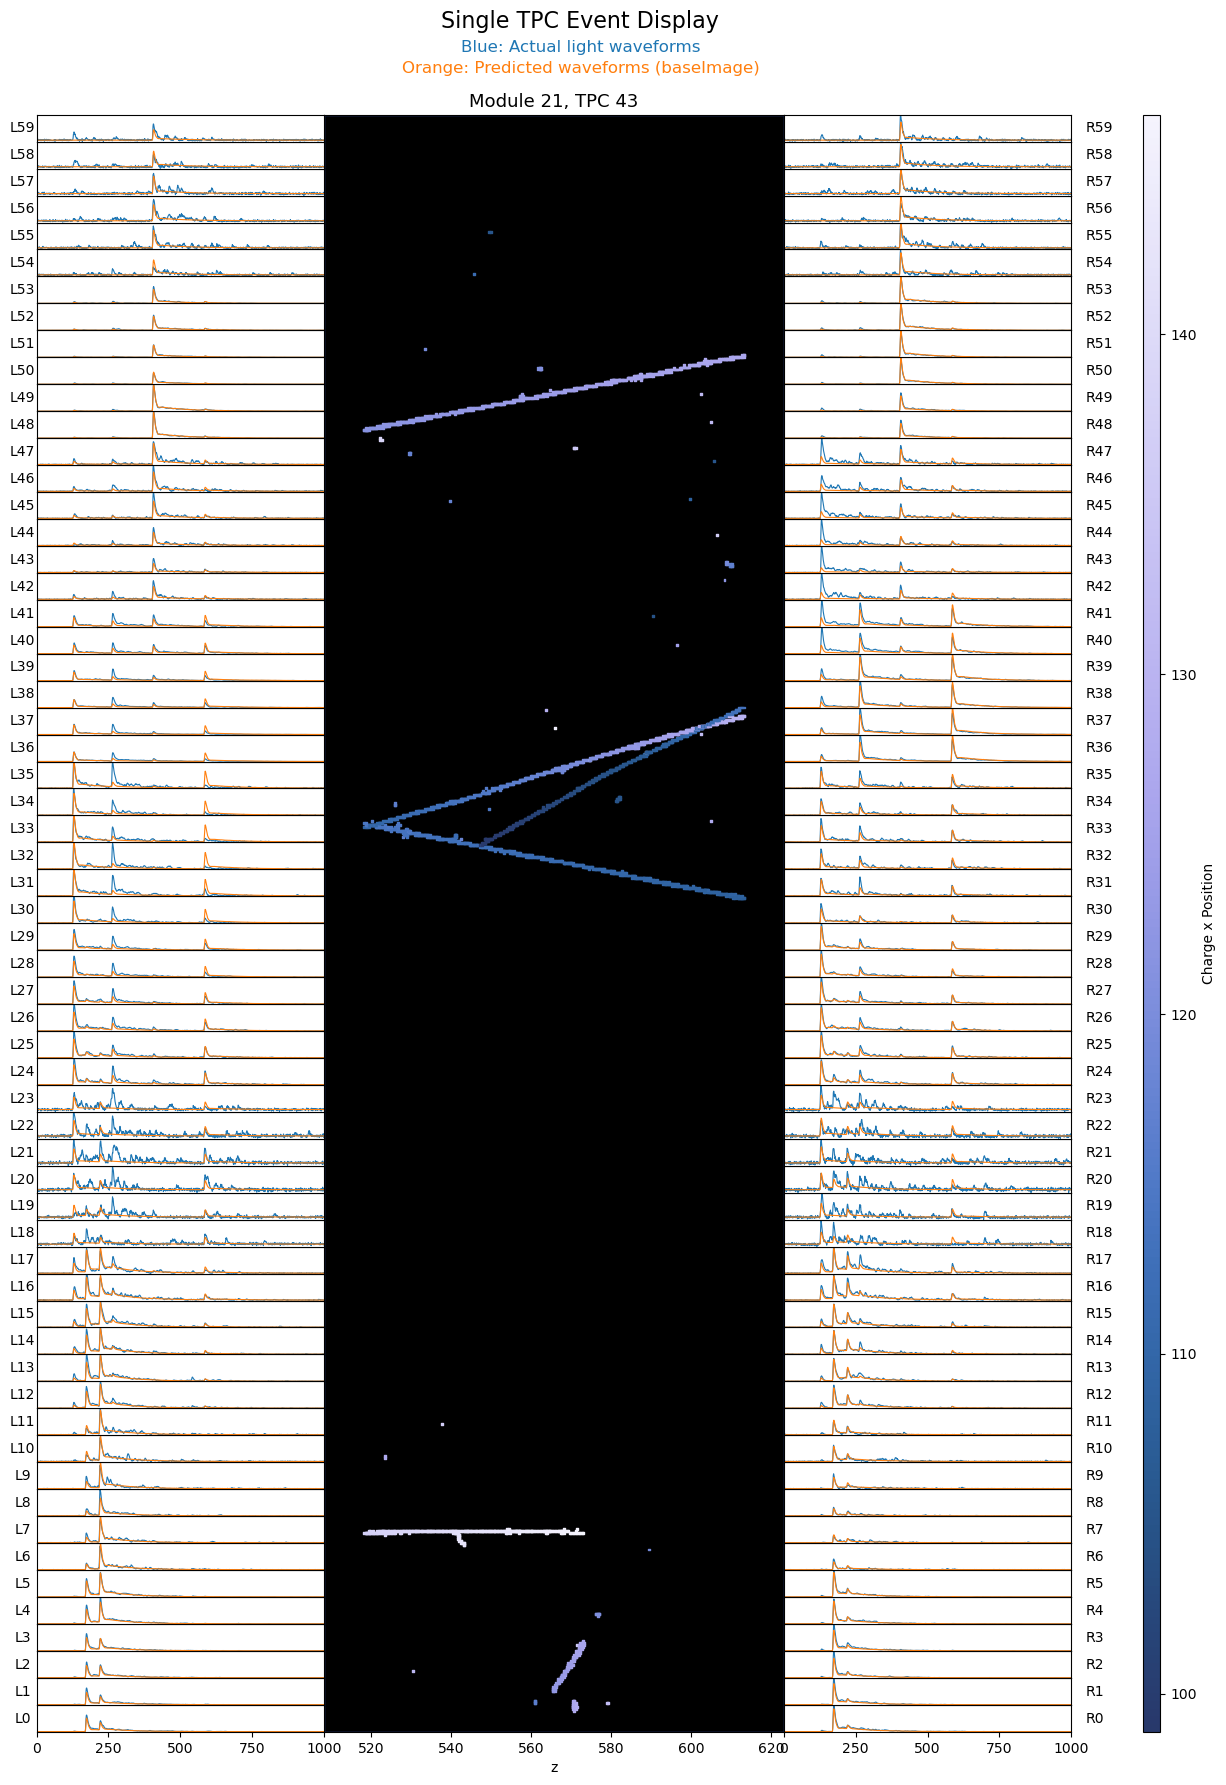

===== AFTER swap:   L86@482, L95@160   (now matches truth) =====
Total energy in TPC 43: 738.70


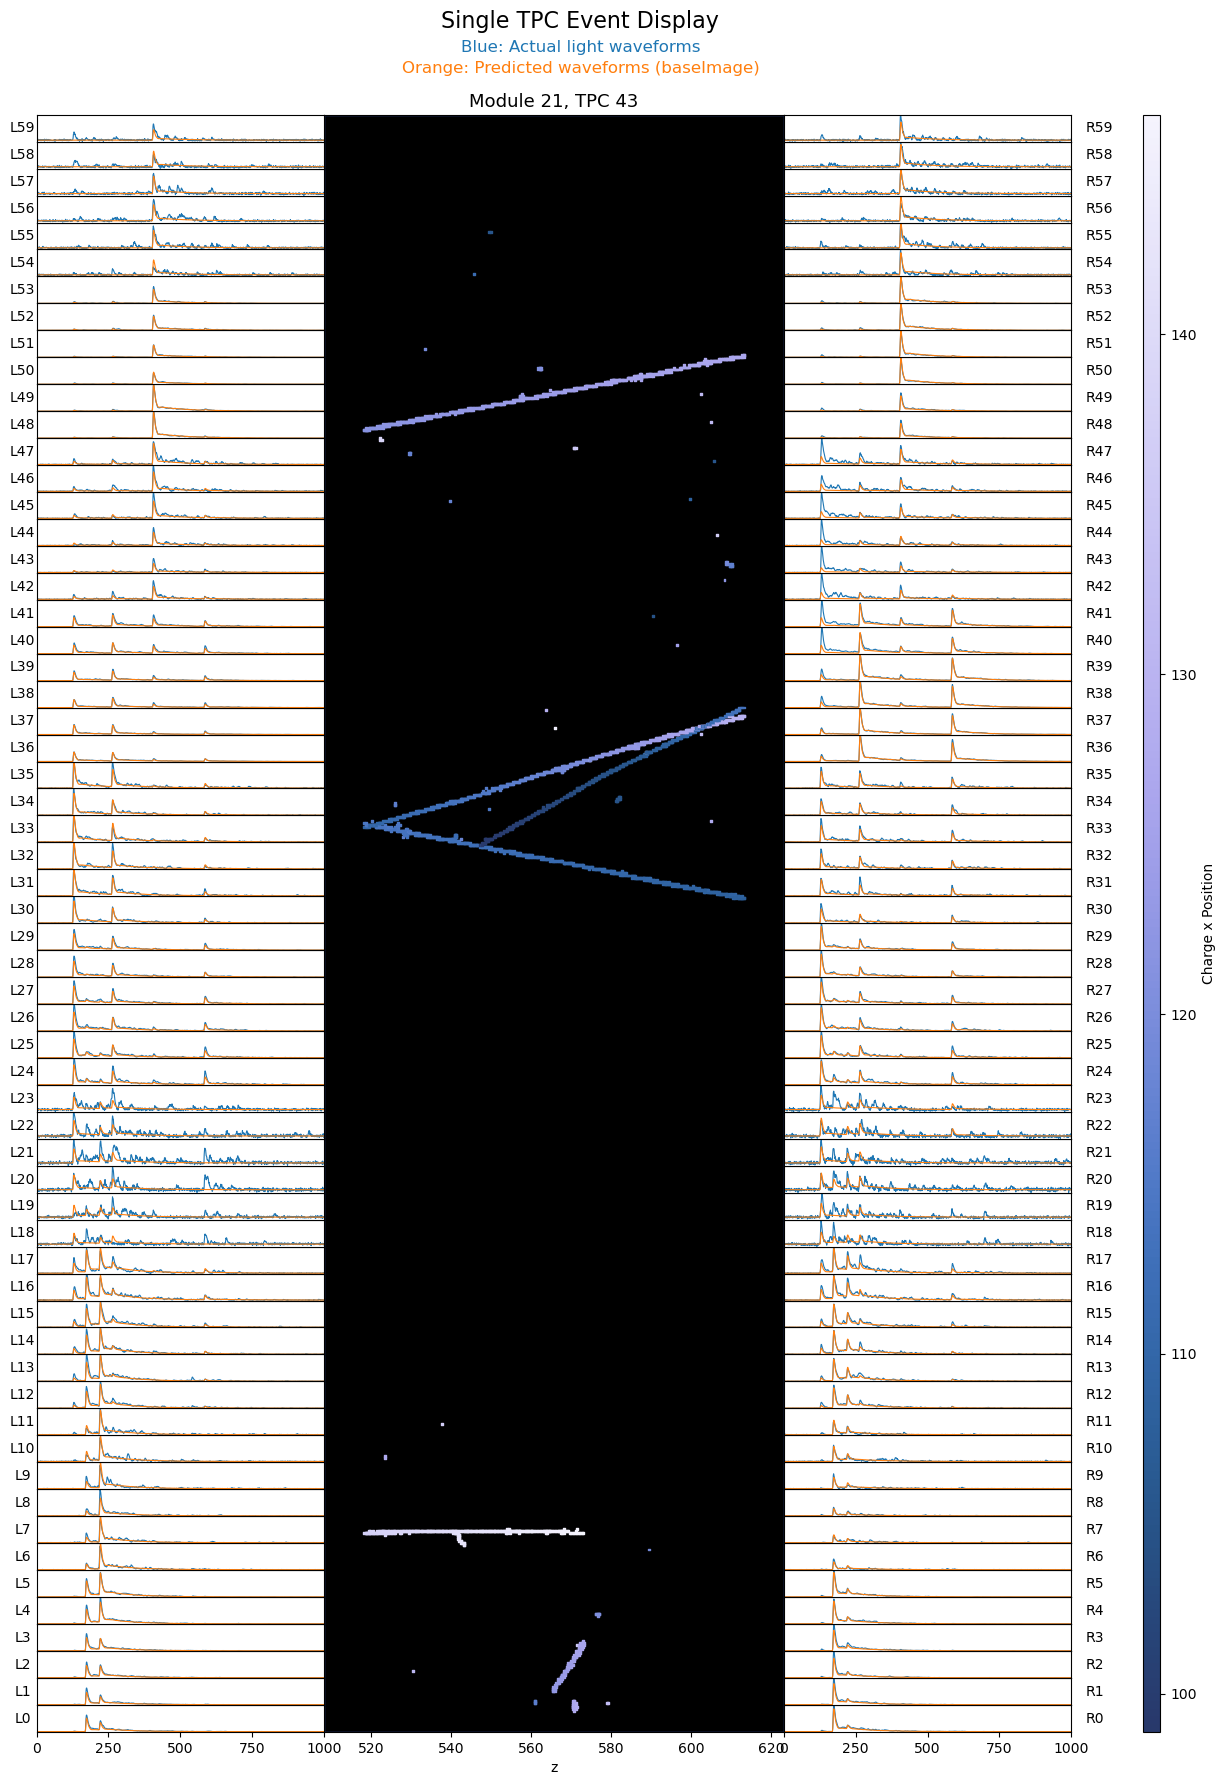

In [13]:
# BEFORE / AFTER per-TPC swap (two figures)
from M5p1 import visualizationTools as vt
best = [r for r in sw if r['mutual'] and r['chi2_better']]
assert best, 'no confident per-TPC swap in SWAP_TPC; try another TPC'
r = best[0]; A, B, tA, tB, c = r['A'], r['B'], r['tA'], r['tB'], SWAP_TPC
PA, PB = EV2.template(A, c), EV2.template(B, c)
act = EV2.actual_light(c); base = EV2.predicted_light(c)
pred_before = np.clip(base, 0, CLIP)
pred_after = np.clip(base - timeinterpolation(PA, shift=tA, baseline=0) - timeinterpolation(PB, shift=tB, baseline=0)
                          + timeinterpolation(PA, shift=tB, baseline=0) + timeinterpolation(PB, shift=tA, baseline=0), 0, CLIP)
_dt = np.dtype([('io_group', 'i4'), ('x', 'f8'), ('y', 'f8'), ('z', 'f8'), ('E', 'f8')])
hf = np.zeros(len(EV2.x), dtype=_dt)
hf['io_group'] = 2*EV2.tpc + 1; hf['x'], hf['y'], hf['z'], hf['E'] = EV2.x, EV2.y, EV2.z, EV2.e
print(f'===== BEFORE swap:  L{A}@{tA:.0f}, L{B}@{tB:.0f}   (truth {r["truthA"]:.0f}/{r["truthB"]:.0f}) =====')
vt.plot_tpc_light_and_charge(EV2.event, c, hf, act, predicted=pred_before)
print(f'===== AFTER swap:   L{A}@{tB:.0f}, L{B}@{tA:.0f}   (now matches truth) =====')
vt.plot_tpc_light_and_charge(EV2.event, c, hf, act, predicted=pred_after)

## 11 · False-swap analysis — where v0.3 REGRESSED (per-TPC)

The per-TPC swap-fix is net-positive, but it *introduced* errors in a few TPCs. Cause: the per-TPC
chi2 was **fooled by a light deficit** — the ML predicts ~78% of the true amplitude, so an
under-predicted flash looks 'unfilled', and swapping a **bigger correct** cluster into it lowers
THIS TPC's chi2 (then cascades). These cells load the **pre-swap (D50)** and **post-swap (v0.3)**
states side by side so you can see exactly what broke and why. Everything here is per-TPC.

Set `PICK_F` to 0/1/2 for the three regressions: TPC61 ev8, TPC26 ev5, TPC38 ev12.

In [14]:
from M5p1 import visualizationTools as vt
from pulse_shapes import timeinterpolation
import glob as _glob

FALSE = [('0000002', 8, 61), ('0000002', 5, 26), ('0000001', 12, 38)]   # (file, event, TPC)
PICK_F = 0
ffile, fev, ftpc = FALSE[PICK_F]
def _load(dumpdir, file, ev):
    return Event(np.load(os.path.join(HERE, dumpdir, 'dumps', f'{file}_ev{ev}.npz'), allow_pickle=True), file, ev)
PRE  = _load('v030D50fix_out', ffile, fev)     # before swap-fix
POST = _load('v030v3_out',     ffile, fev)     # after swap-fix (v0.3)

# the swaps v0.3 applied IN THIS TPC (from the JSONL audit)
aud = []
for fp in _glob.glob(os.path.join(HERE, 'v030v3_out', 'groups_worker*.jsonl')):
    for l in open(fp):
        if not l.strip(): continue
        r = json.loads(l)
        if r['file'].split('.')[-3] == ffile and r['event'] == fev:
            aud = [a for a in ((r.get('phase3') or {}).get('swap_audit') or []) if a.get('tpc') == ftpc]
print(f'TPC{ftpc} ev{fev}: v0.3 applied {len(aud)} per-TPC swaps here')
for a in aud:
    print(f"   L{a['A']}<->L{a['B']}  {a['tA']}<->{a['tB']}  chi2_ratio={a['chi2_ratio']}  truth {a.get('truthA')}/{a.get('truthB')}  good={a.get('good')}")

# per-cluster placement: pre -> post vs truth (who got broken)
print(f'\nTPC{ftpc} cluster placements (pre -> post, truth):')
for L in sorted(set(int(x) for x in PRE.labels[(PRE.tpc == ftpc) & (PRE.labels >= 0)])):
    mp = (PRE.labels == L) & (PRE.tpc == ftpc)
    if mp.sum() < 20: continue
    ma = (POST.labels == L) & (POST.tpc == ftpc)
    trv = PRE.truth_t0[mp][np.isfinite(PRE.truth_t0[mp])]
    tp = np.median(PRE.ts_final[mp]); ta = (np.median(POST.ts_final[ma]) if ma.any() else np.nan)
    tr = (np.median(trv) if trv.size else np.nan)
    tag = 'ok' if abs(ta - tr) <= 10 else ('BROKEN (was correct!)' if abs(tp - tr) <= 10 else 'wrong')
    print(f'  L{L:<5} {tp:6.0f} -> {ta:6.0f}  (truth {tr:6.0f})  {tag}')

TPC61 ev8: v0.3 applied 3 per-TPC swaps here
   L126<->L1137  599.0<->166.0  chi2_ratio=0.241  truth 598.7/178.9  good=False
   L122<->L1137  287.5<->599.0  chi2_ratio=0.258  truth 287.4/178.9  good=False
   L122<->L125  599.0<->523.0  chi2_ratio=0.829  truth 287.4/522.7  good=False

TPC61 cluster placements (pre -> post, truth):
  L2        171 ->    171  (truth    623)  wrong
  L122      288 ->    523  (truth    287)  BROKEN (was correct!)
  L123      311 ->    311  (truth    311)  ok
  L124      171 ->    171  (truth    171)  ok
  L125      523 ->    599  (truth    522)  BROKEN (was correct!)
  L126      599 ->    166  (truth    599)  BROKEN (was correct!)
  L127      614 ->    614  (truth    614)  ok
  L1132     288 ->    288  (truth    287)  ok
  L1133     286 ->    286  (truth    287)  ok
  L1135     286 ->    286  (truth    287)  ok
  L1137     166 ->    288  (truth    179)  wrong


### Before / after — the deficit that fooled the chi2
Blue = actual light, orange = predicted. In BEFORE, look for a flash where orange sits well *below*
blue (a deficit); AFTER, the swap moved a bigger cluster there — lower chi2, but wrong truth.

BEFORE (D50, pre swap-fix):
Total energy in TPC 61: 989.48


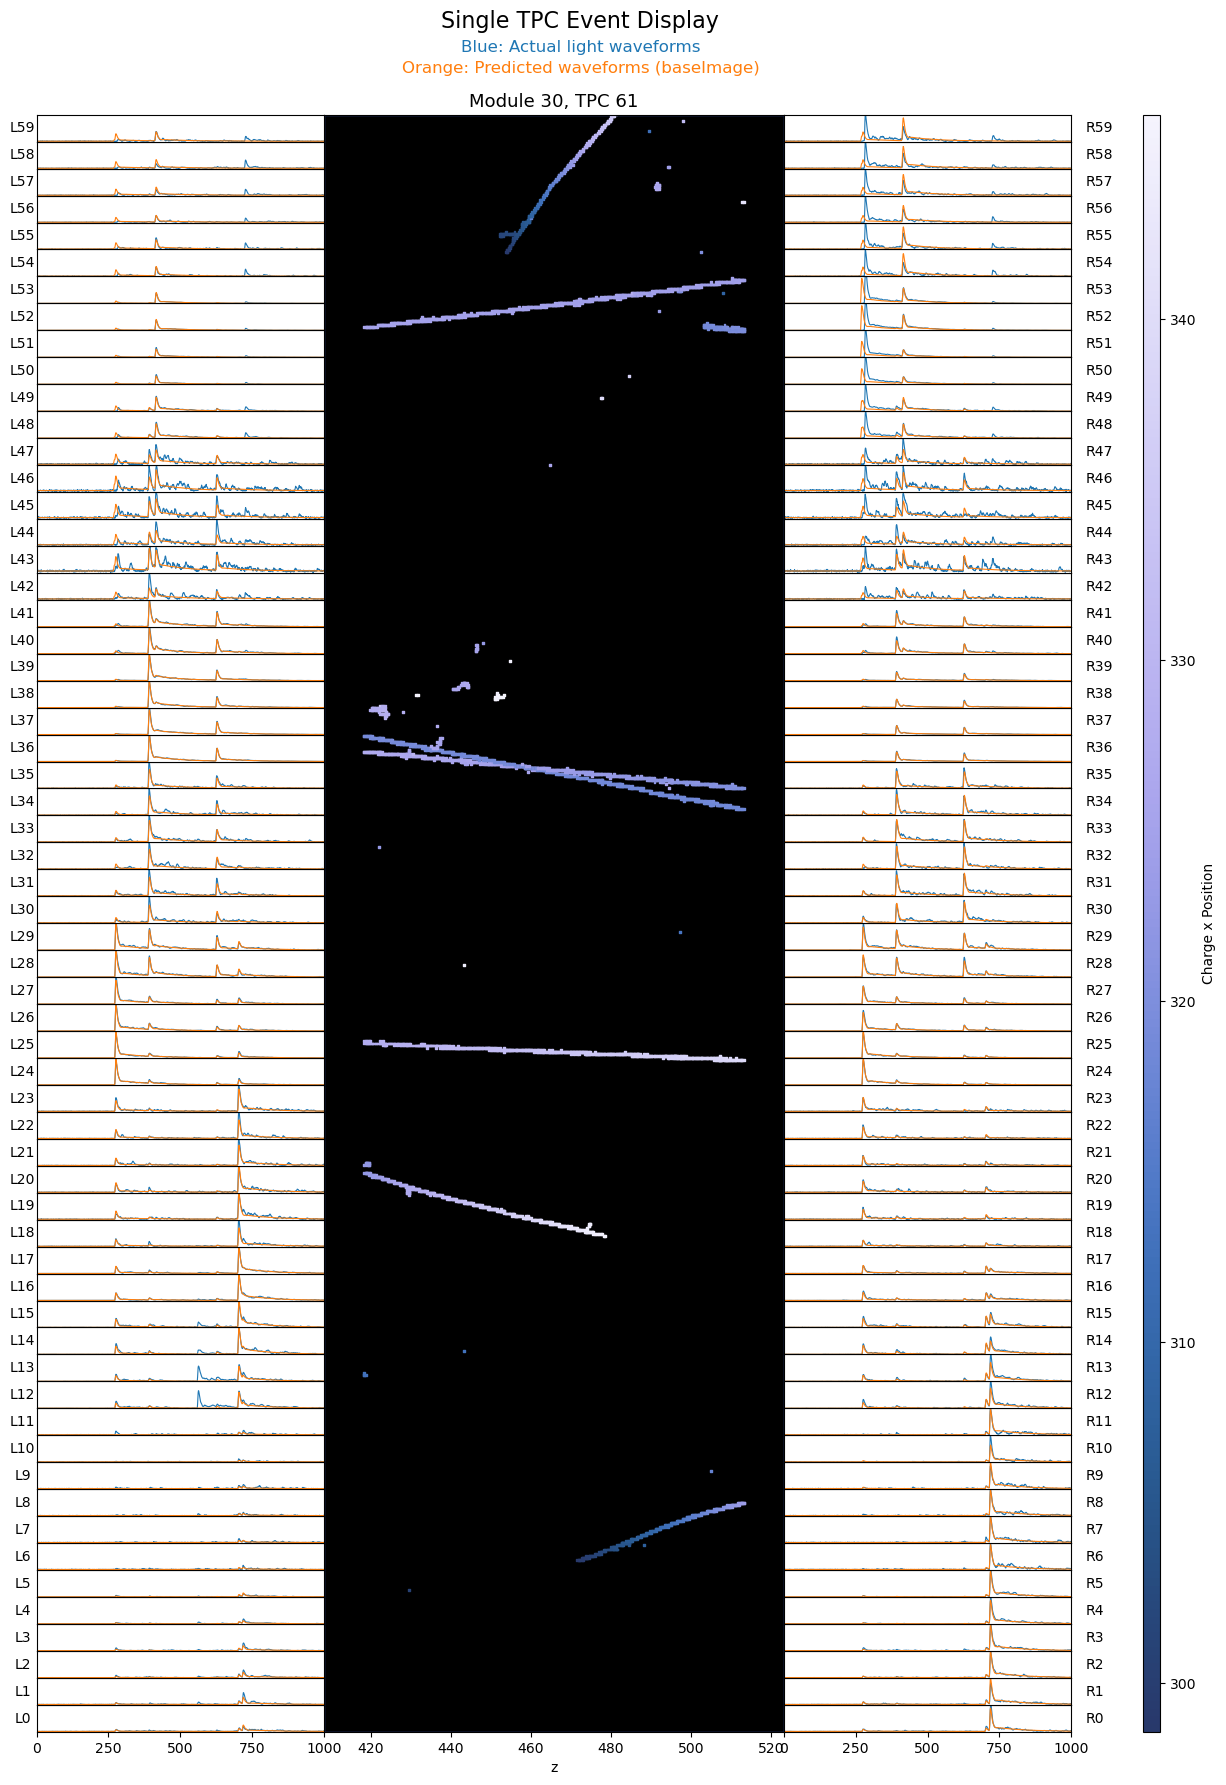

AFTER (v0.3, post swap-fix):
Total energy in TPC 61: 989.48


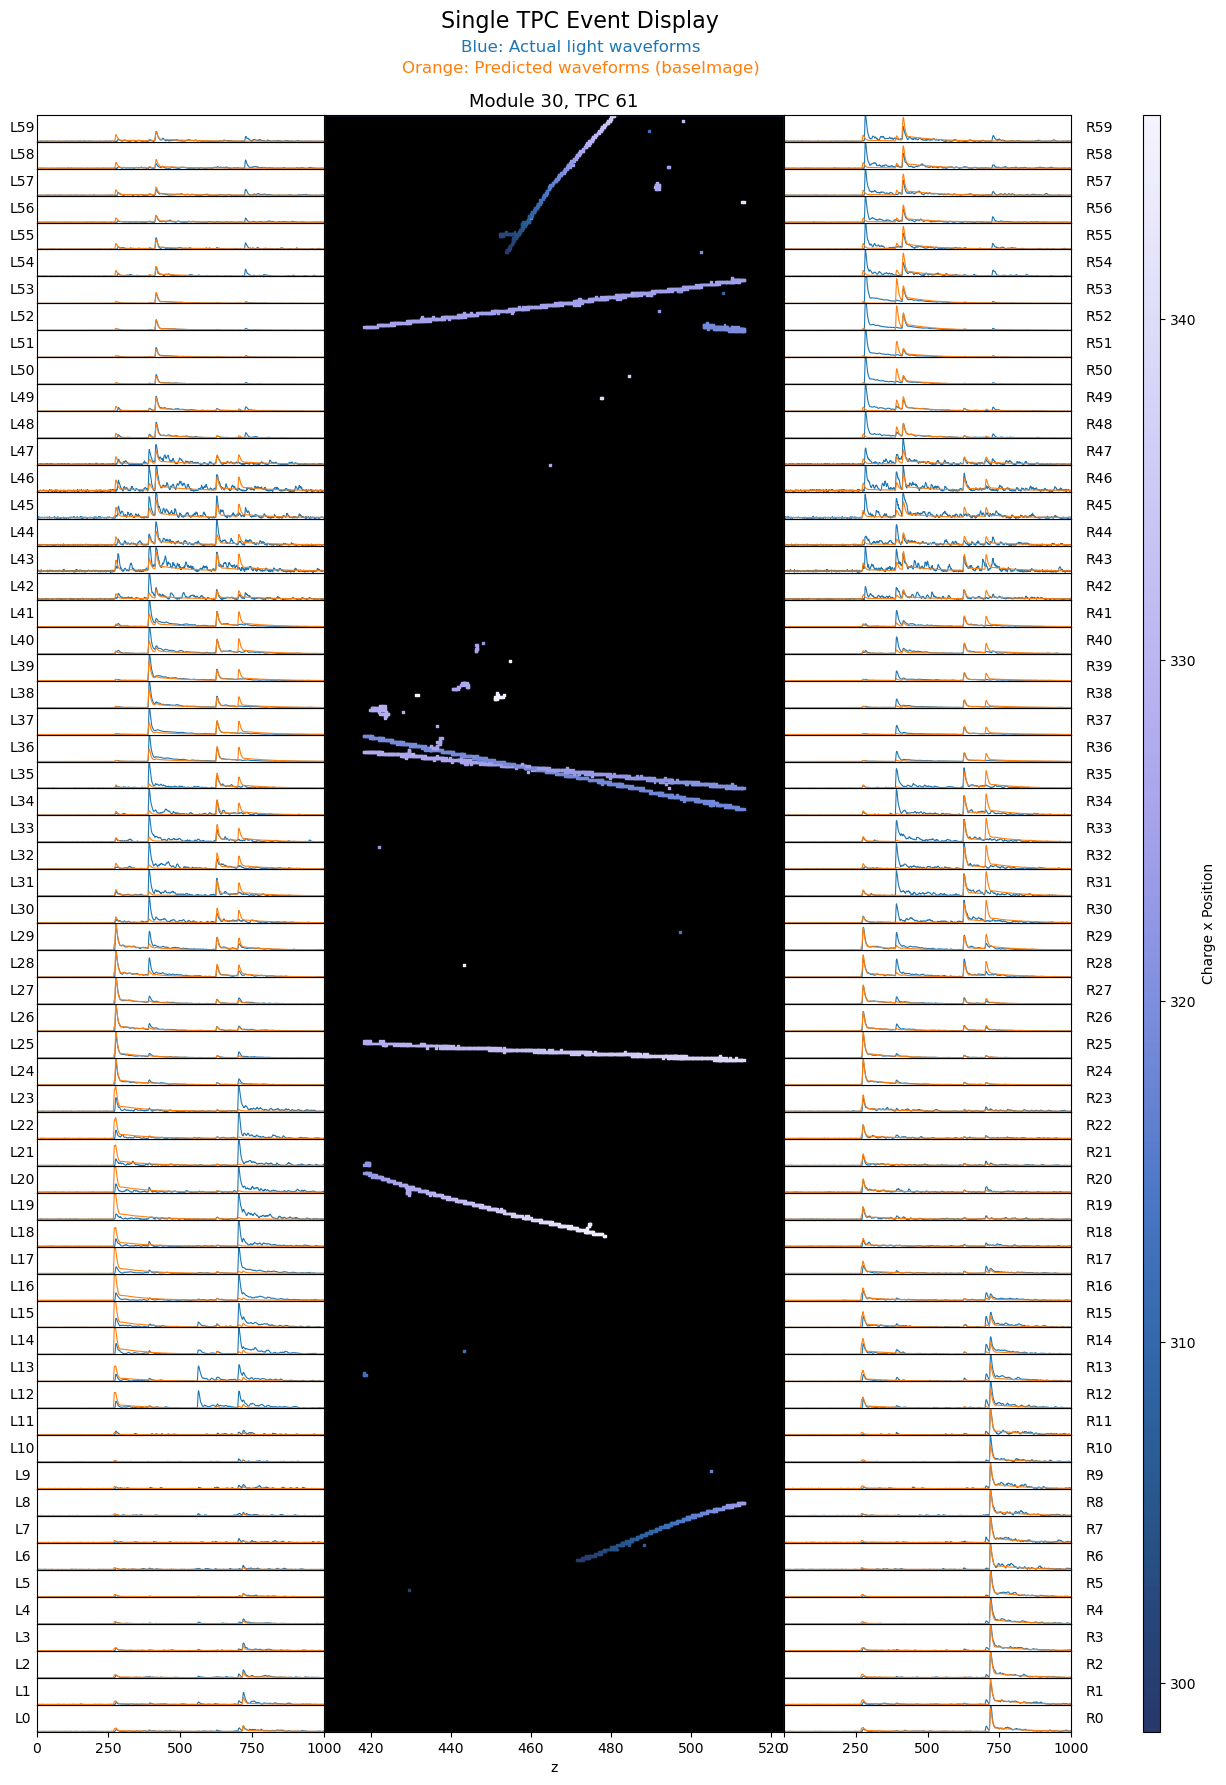

In [15]:
def _hits(ev):
    dt = np.dtype([('io_group','i4'),('x','f8'),('y','f8'),('z','f8'),('E','f8')])
    h = np.zeros(len(ev.x), dtype=dt); h['io_group'] = 2*ev.tpc + 1
    h['x'],h['y'],h['z'],h['E'] = ev.x, ev.y, ev.z, ev.e; return h
print('BEFORE (D50, pre swap-fix):')
vt.plot_tpc_light_and_charge(fev, ftpc, _hits(PRE), PRE.actual_light(ftpc), predicted=np.clip(PRE.predicted_light(ftpc),0,CLIP))
print('AFTER (v0.3, post swap-fix):')
vt.plot_tpc_light_and_charge(fev, ftpc, _hits(POST), POST.actual_light(ftpc), predicted=np.clip(POST.predicted_light(ftpc),0,CLIP))

### Why the chi2 accepted it — and whether the new spatial gate rejects it
The chi2 is amplitude-sensitive (fooled by the deficit). The **spatial cosine** is shape-normalized:
it asks whether each cluster's charge *position* matches the flash pattern, so a correctly-placed
cluster will NOT prefer the swap. `swap_fix` now requires BOTH a chi2 drop AND both parts to prefer
the swap spatially (`spatial_gate=True`). Here we re-derive both on the pre-swap state.

In [16]:
def _tmpl(A, c):
    return POST.template(A, c) if POST.template(A, c) is not None else PRE.template(A, c)  # label-tpc invariant
def _flash(ev, c, t0, win=4):
    a = ev.actual_light(c); t = int(round(t0)) + PEAK
    col = a[:, max(0, t-win):min(a.shape[1], t+win+1)]; return col.sum(1), col.max(1) >= 0.98*CLIP
def _cos(u, v, m):
    u, v = u[~m], v[~m]; nu, nv = np.linalg.norm(u), np.linalg.norm(v)
    return float(u@v/(nu*nv)) if nu and nv else 0.0
for a in aud:
    A, B, tA, tB = a['A'], a['B'], a['tA'], a['tB']
    PA, PB = _tmpl(A, ftpc), _tmpl(B, ftpc)
    if PA is None or PB is None:
        print(f"  L{A}<->L{B}: template not dumped"); continue
    pa, pb = PA.sum(1), PB.sum(1)
    fA, sA = _flash(PRE, ftpc, tA); fB, sB = _flash(PRE, ftpc, tB)
    gA = _cos(pa, fB, sB) - _cos(pa, fA, sA)   # A prefers B's flash spatially?
    gB = _cos(pb, fA, sA) - _cos(pb, fB, sB)   # B prefers A's flash spatially?
    verdict = 'gate REJECTS -> fix works' if not (gA > 0 and gB > 0) else 'gate would STILL allow (needs more)'
    print(f"  swap L{A}(@{tA:.0f})<->L{B}(@{tB:.0f}): chi2_ratio={a['chi2_ratio']} (accepted; lowers THIS TPC loss)")
    print(f"     spatial gA={gA:+.3f}  gB={gB:+.3f}   -> {verdict}")

  L126<->L1137: template not dumped
  L122<->L1137: template not dumped
  L122<->L125: template not dumped
